<a href="https://colab.research.google.com/github/hiba-essid/DeteChange/blob/main/DetectChange_PartieA_EuroSAT_MobileNetV2_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DetectChange : Partie A. Classification mono-date EuroSAT (MobileNetV2)

**Objectif** : apprendre une représentation des classes d'occupation du sol sur EuroSAT RGB, puis réutiliser l'encodeur dans la partie B (détection de changement).

**Contenu du notebook**
1. Configuration et reproductibilité
2. Données : découpage stratifié sans fuite train / val / test
3. Augmentations
4. Modèles : tête seule, fine-tuning partiel, CNN compact
5. Entraînement (early stopping sur le F1 macro de validation)
6. Évaluation : accuracy, précision, rappel, F1 macro, matrice de confusion, paramètres, taille, temps d'inférence
7. Analyse des erreurs
8. Sauvegarde de l'encodeur pour la partie B

> Prévu pour Google Colab / Kaggle (GPU). Fonctionne aussi en local, plus lentement sans GPU.

## 1. Configuration et reproductibilité

In [1]:
import os, time, random, json, copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, confusion_matrix, classification_report)

CFG = dict(
    seed=42,
    img_size=96,          # EuroSAT = 64x64 ; on agrandit pour MobileNetV2 (essayer 128 ou 224)
    batch_size=128,
    num_workers=2,
    epochs_head=8,
    epochs_ft=15,
    epochs_cnn=25,
    lr_head=1e-3,         # tête seule
    lr_ft_backbone=1e-4,  # fine-tuning : blocs dégelés
    lr_ft_head=1e-3,      # fine-tuning : nouvelle tête
    lr_cnn=2e-3,
    weight_decay=1e-4,
    patience=4,           # early stopping (epochs sans amélioration du F1 macro val)
    val_size=0.15,
    test_size=0.15,
    unfreeze_from=14,     # MobileNetV2.features[14:] dégelés en fine-tuning partiel
    data_root="./data",
    out_dir="./outputs",
)
Path(CFG["out_dir"]).mkdir(parents=True, exist_ok=True)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(CFG["seed"])
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device, "| torch", torch.__version__)

Device : cuda | torch 2.14.1+cu130


## 2. Données et découpage sans fuite

- EuroSAT RGB (27 000 patchs, 10 classes) est téléchargé via `torchvision`.
- Le découpage est **stratifié** et fixé par la graine, et réalisé **sur les indices avant toute augmentation** : les augmentations ne s'appliquent qu'au train.
- On vérifie explicitement qu'aucun indice n'est partagé entre les trois ensembles.

In [2]:
base = datasets.EuroSAT(root=CFG["data_root"], download=True)   # PIL images, sans transform
classes = base.classes
targets = np.array(base.targets)
n_classes = len(classes)
print(len(base), "images |", n_classes, "classes :", classes)

idx_all = np.arange(len(base))
idx_trainval, idx_test = train_test_split(
    idx_all, test_size=CFG["test_size"], stratify=targets, random_state=CFG["seed"])
idx_train, idx_val = train_test_split(
    idx_trainval, test_size=CFG["val_size"] / (1 - CFG["test_size"]),
    stratify=targets[idx_trainval], random_state=CFG["seed"])

# Contrôle anti-fuite
s_tr, s_va, s_te = set(idx_train), set(idx_val), set(idx_test)
assert not (s_tr & s_va) and not (s_tr & s_te) and not (s_va & s_te), "Fuite entre ensembles !"
print(f"train={len(idx_train)}  val={len(idx_val)}  test={len(idx_test)}")

# Répartition par classe
split_df = pd.DataFrame({
    "classe": classes,
    "train": np.bincount(targets[idx_train], minlength=n_classes),
    "val":   np.bincount(targets[idx_val],   minlength=n_classes),
    "test":  np.bincount(targets[idx_test],  minlength=n_classes),
})
split_df

100%|██████████| 94.3M/94.3M [00:00<00:00, 154MB/s]


27000 images | 10 classes : ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
train=18899  val=4051  test=4050


,classe,train,val,test
0,AnnualCrop,2100,450,450
1,Forest,2100,450,450
2,HerbaceousVegetation,2099,451,450
3,Highway,1750,375,375
4,Industrial,1750,375,375
5,Pasture,1400,300,300
6,PermanentCrop,1750,375,375
7,Residential,2100,450,450
8,River,1750,375,375
9,SeaLake,2100,450,450


## 3. Prétraitements et augmentations

- **Train** : flips horizontal/vertical, rotation par multiples de 90°, léger changement de luminosité/contraste. Ces augmentations sont géométriques et préservent la radiométrie.
- **Val / test** : redimensionnement et normalisation uniquement.
- Normalisation avec les statistiques ImageNet, car l'encodeur est pré-entraîné sur ImageNet.

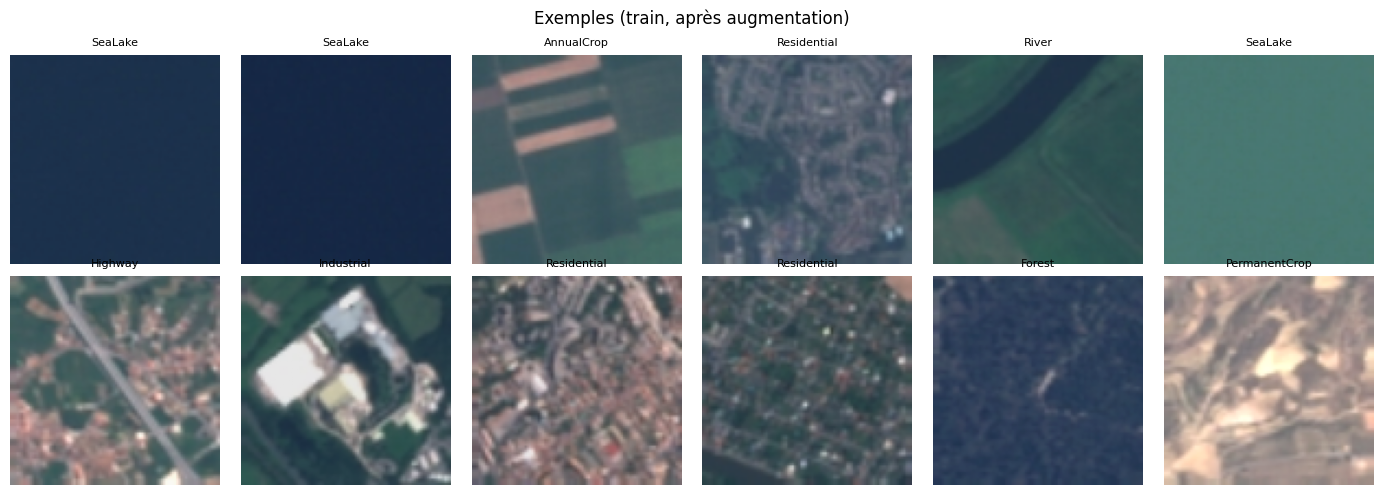

In [3]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
S = CFG["img_size"]

train_tf = transforms.Compose([
    transforms.Resize((S, S)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomChoice([transforms.RandomRotation((a, a)) for a in (0, 90, 180, 270)]),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((S, S)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

ds_train = Subset(datasets.EuroSAT(CFG["data_root"], transform=train_tf), idx_train)
ds_val   = Subset(datasets.EuroSAT(CFG["data_root"], transform=eval_tf),  idx_val)
ds_test  = Subset(datasets.EuroSAT(CFG["data_root"], transform=eval_tf),  idx_test)

def make_loader(ds, shuffle):
    g = torch.Generator(); g.manual_seed(CFG["seed"])
    return DataLoader(ds, batch_size=CFG["batch_size"], shuffle=shuffle,
                      num_workers=CFG["num_workers"], pin_memory=(device.type == "cuda"),
                      generator=g if shuffle else None)

train_loader = make_loader(ds_train, True)
val_loader   = make_loader(ds_val, False)
test_loader  = make_loader(ds_test, False)

# Aperçu d'un lot d'entraînement augmenté
x, y = next(iter(train_loader))
mean = torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1); std = torch.tensor(IMAGENET_STD).view(1, 3, 1, 1)
imgs = (x[:12] * std + mean).clamp(0, 1)
fig, axs = plt.subplots(2, 6, figsize=(14, 5))
for a, im, lab in zip(axs.ravel(), imgs, y[:12]):
    a.imshow(im.permute(1, 2, 0)); a.set_title(classes[lab], fontsize=8); a.axis("off")
plt.suptitle("Exemples (train, après augmentation)"); plt.tight_layout(); plt.show()

## 4. Modèles

| Nom | Description |
|---|---|
| `mnv2_head` | MobileNetV2 ImageNet, **encodeur gelé**, seule la tête est entraînée |
| `mnv2_finetune` | Dégel partiel : derniers blocs (`features[14:]`) + tête |
| `cnn_compact` | Petit CNN entraîné **from scratch** (référence) |

Les couches BatchNorm gelées restent en mode `eval` pendant l'entraînement, ce qui évite de dégrader les statistiques ImageNet.

In [4]:
def build_mobilenet(mode, n_classes):
    m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
    in_f = m.classifier[1].in_features
    m.classifier = nn.Sequential(nn.Dropout(0.2), nn.Linear(in_f, n_classes))
    for p in m.features.parameters():
        p.requires_grad = False
    if mode == "finetune":
        for p in m.features[CFG["unfreeze_from"]:].parameters():
            p.requires_grad = True
    return m

class CompactCNN(nn.Module):
    def __init__(self, n_classes, widths=(32, 64, 128, 256)):
        super().__init__()
        layers, c_in = [], 3
        for w in widths:
            layers += [nn.Conv2d(c_in, w, 3, padding=1, bias=False), nn.BatchNorm2d(w), nn.ReLU(inplace=True),
                       nn.Conv2d(w, w, 3, padding=1, bias=False), nn.BatchNorm2d(w), nn.ReLU(inplace=True),
                       nn.MaxPool2d(2)]
            c_in = w
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                                        nn.Dropout(0.3), nn.Linear(c_in, n_classes))
    def forward(self, x):
        return self.classifier(self.features(x))

def get_model(name):
    if name == "mnv2_head":     return build_mobilenet("head", n_classes)
    if name == "mnv2_finetune": return build_mobilenet("finetune", n_classes)
    if name == "cnn_compact":   return CompactCNN(n_classes)
    raise ValueError(name)

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def model_size_mb(model):
    n = sum(p.numel() * p.element_size() for p in model.parameters())
    n += sum(b.numel() * b.element_size() for b in model.buffers())
    return n / 1e6

for n in ["mnv2_head", "mnv2_finetune", "cnn_compact"]:
    m = get_model(n); t, tr = count_params(m)
    print(f"{n:15s} total={t/1e6:5.2f} M  entraînables={tr/1e6:5.2f} M  taille={model_size_mb(m):5.1f} Mo")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 111MB/s]


mnv2_head       total= 2.24 M  entraînables= 0.01 M  taille=  9.1 Mo
mnv2_finetune   total= 2.24 M  entraînables= 1.69 M  taille=  9.1 Mo
cnn_compact     total= 1.18 M  entraînables= 1.18 M  taille=  4.7 Mo


## 5. Entraînement

- Optimiseur AdamW, scheduler cosinus, précision mixte sur GPU.
- **Early stopping** et sélection du meilleur modèle sur le **F1 macro de validation** (le test n'est jamais utilisé pour choisir).

In [5]:
def set_train_mode(model):
    model.train()
    # BatchNorm sans paramètres entraînables -> reste en eval (statistiques figées)
    for m in model.modules():
        if isinstance(m, nn.BatchNorm2d) and not any(p.requires_grad for p in m.parameters()):
            m.eval()

@torch.no_grad()
def predict(model, loader):
    model.eval()
    ys, ps, losses = [], [], []
    crit = nn.CrossEntropyLoss(reduction="sum")
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        out = model(x)
        losses.append(crit(out, y).item())
        ys.append(y.cpu()); ps.append(out.argmax(1).cpu())
    y_true, y_pred = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return y_true, y_pred, sum(losses) / len(y_true)

def make_optimizer(name, model, epochs):
    if name == "mnv2_head":
        params = [{"params": model.classifier.parameters(), "lr": CFG["lr_head"]}]
    elif name == "mnv2_finetune":
        params = [
            {"params": [p for p in model.features.parameters() if p.requires_grad], "lr": CFG["lr_ft_backbone"]},
            {"params": model.classifier.parameters(), "lr": CFG["lr_ft_head"]},
        ]
    else:
        params = [{"params": model.parameters(), "lr": CFG["lr_cnn"]}]
    opt = torch.optim.AdamW(params, weight_decay=CFG["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    return opt, sched

def train_model(name, epochs, seed=None):
    set_seed(CFG["seed"] if seed is None else seed)
    model = get_model(name).to(device)
    opt, sched = make_optimizer(name, model, epochs)
    crit = nn.CrossEntropyLoss()
    use_amp = device.type == "cuda"
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

    hist, best_f1, best_state, bad = [], -1, None, 0
    t0 = time.time()
    for ep in range(1, epochs + 1):
        set_train_mode(model)
        run_loss, n = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                loss = crit(model(x), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run_loss += loss.item() * len(y); n += len(y)
        sched.step()

        yv, pv, vloss = predict(model, val_loader)
        vacc = accuracy_score(yv, pv); vf1 = f1_score(yv, pv, average="macro")
        hist.append(dict(epoch=ep, train_loss=run_loss / n, val_loss=vloss, val_acc=vacc, val_f1=vf1))
        print(f"[{name}] ep {ep:02d}/{epochs} | train_loss {run_loss/n:.4f} | val_loss {vloss:.4f} "
              f"| val_acc {vacc:.4f} | val_F1 {vf1:.4f}")

        if vf1 > best_f1:
            best_f1, best_state, bad = vf1, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= CFG["patience"]:
                print(f"Early stopping à l'epoch {ep}"); break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist), time.time() - t0

## 6. Évaluation : fonctions de mesure (qualité et efficacité)

In [6]:
@torch.no_grad()
def measure_inference_ms(model, dev, n_runs=100, warmup=10, batch=1):
    m = copy.deepcopy(model).to(dev).eval()
    x = torch.randn(batch, 3, S, S, device=dev)
    for _ in range(warmup): m(x)
    if dev.type == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(n_runs): m(x)
    if dev.type == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t0) / n_runs * 1000

def evaluate(name, model, train_time=None):
    y_true, y_pred, loss = predict(model, test_loader)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    total, trainable = count_params(model)
    res = dict(
        modele=name,
        accuracy=accuracy_score(y_true, y_pred),
        precision_macro=p, rappel_macro=r, f1_macro=f1,
        params_M=total / 1e6, params_entrainables_M=trainable / 1e6,
        taille_Mo=model_size_mb(model),
        inference_ms_img_cpu=measure_inference_ms(model, torch.device("cpu"), n_runs=30),
        inference_ms_img_gpu=measure_inference_ms(model, device) if device.type == "cuda" else np.nan,
        temps_train_s=train_time,
    )
    return res, y_true, y_pred

## 7. Lancement des expériences

In [ ]:
EXPERIMENTS = [("mnv2_head", CFG["epochs_head"]),
               ("mnv2_finetune", CFG["epochs_ft"]),
               ("cnn_compact", CFG["epochs_cnn"])]   # retirer cnn_compact pour gagner du temps

results, histories, preds, trained = [], {}, {}, {}
for name, ep in EXPERIMENTS:
    model, hist, tt = train_model(name, ep)
    res, y_true, y_pred = evaluate(name, model, tt)
    # F1 de validation du modèle retenu (critère de sélection)
    yv, pv, _ = predict(model, val_loader)
    res["val_f1_macro"] = f1_score(yv, pv, average="macro")
    results.append(res); histories[name] = hist; preds[name] = (y_true, y_pred); trained[name] = model
    print()

res_df = pd.DataFrame(results).set_index("modele")
res_df.round(4)

/tmp/ipykernel_1643/2845516982.py:41: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


[mnv2_head] ep 01/8 | train_loss 0.9239 | val_loss 0.5603 | val_acc 0.8684 | val_F1 0.8658
[mnv2_head] ep 02/8 | train_loss 0.4895 | val_loss 0.4154 | val_acc 0.8869 | val_F1 0.8854
[mnv2_head] ep 03/8 | train_loss 0.3966 | val_loss 0.3638 | val_acc 0.8951 | val_F1 0.8933
[mnv2_head] ep 04/8 | train_loss 0.3583 | val_loss 0.3392 | val_acc 0.8995 | val_F1 0.8981
[mnv2_head] ep 05/8 | train_loss 0.3387 | val_loss 0.3235 | val_acc 0.9035 | val_F1 0.9018
[mnv2_head] ep 06/8 | train_loss 0.3267 | val_loss 0.3182 | val_acc 0.9030 | val_F1 0.9011
[mnv2_head] ep 07/8 | train_loss 0.3205 | val_loss 0.3148 | val_acc 0.9059 | val_F1 0.9039
[mnv2_head] ep 08/8 | train_loss 0.3171 | val_loss 0.3107 | val_acc 0.9057 | val_F1 0.9038



/tmp/ipykernel_1643/2845516982.py:41: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


[mnv2_finetune] ep 01/15 | train_loss 0.3405 | val_loss 0.1586 | val_acc 0.9452 | val_F1 0.9432
[mnv2_finetune] ep 02/15 | train_loss 0.1660 | val_loss 0.1360 | val_acc 0.9531 | val_F1 0.9514
[mnv2_finetune] ep 03/15 | train_loss 0.1347 | val_loss 0.1260 | val_acc 0.9561 | val_F1 0.9544
[mnv2_finetune] ep 04/15 | train_loss 0.1147 | val_loss 0.1213 | val_acc 0.9568 | val_F1 0.9551
[mnv2_finetune] ep 05/15 | train_loss 0.0996 | val_loss 0.1118 | val_acc 0.9610 | val_F1 0.9589
[mnv2_finetune] ep 06/15 | train_loss 0.0885 | val_loss 0.1069 | val_acc 0.9610 | val_F1 0.9596
[mnv2_finetune] ep 07/15 | train_loss 0.0783 | val_loss 0.1053 | val_acc 0.9622 | val_F1 0.9604
[mnv2_finetune] ep 08/15 | train_loss 0.0759 | val_loss 0.0971 | val_acc 0.9667 | val_F1 0.9651
[mnv2_finetune] ep 09/15 | train_loss 0.0597 | val_loss 0.1019 | val_acc 0.9672 | val_F1 0.9657
[mnv2_finetune] ep 10/15 | train_loss 0.0567 | val_loss 0.1027 | val_acc 0.9649 | val_F1 0.9635
[mnv2_finetune] ep 11/15 | train_loss 0.

/tmp/ipykernel_1643/2845516982.py:41: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


[cnn_compact] ep 01/25 | train_loss 1.0552 | val_loss 1.3240 | val_acc 0.5816 | val_F1 0.5782
[cnn_compact] ep 02/25 | train_loss 0.6797 | val_loss 0.8938 | val_acc 0.7156 | val_F1 0.6849
[cnn_compact] ep 03/25 | train_loss 0.5326 | val_loss 0.6786 | val_acc 0.7707 | val_F1 0.7580
[cnn_compact] ep 04/25 | train_loss 0.4491 | val_loss 0.7764 | val_acc 0.7499 | val_F1 0.7295
[cnn_compact] ep 05/25 | train_loss 0.3850 | val_loss 1.2399 | val_acc 0.7391 | val_F1 0.7121
[cnn_compact] ep 06/25 | train_loss 0.3323 | val_loss 0.3759 | val_acc 0.8689 | val_F1 0.8649
[cnn_compact] ep 07/25 | train_loss 0.3018 | val_loss 0.2706 | val_acc 0.9047 | val_F1 0.9014
[cnn_compact] ep 08/25 | train_loss 0.2733 | val_loss 0.2389 | val_acc 0.9203 | val_F1 0.9192
[cnn_compact] ep 09/25 | train_loss 0.2465 | val_loss 0.2081 | val_acc 0.9282 | val_F1 0.9264
[cnn_compact] ep 10/25 | train_loss 0.2276 | val_loss 0.4183 | val_acc 0.8665 | val_F1 0.8665
[cnn_compact] ep 11/25 | train_loss 0.2015 | val_loss 0.2197

In [ ]:
# Courbes d'apprentissage
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for name, h in histories.items():
    axs[0].plot(h["epoch"], h["val_loss"], marker="o", label=name)
    axs[1].plot(h["epoch"], h["val_f1"], marker="o", label=name)
axs[0].set_title("Loss de validation"); axs[1].set_title("F1 macro de validation")
for a in axs: a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()

In [ ]:
# Tableau comparatif (à reporter dans le rapport)
cols = ["val_f1_macro", "accuracy", "precision_macro", "rappel_macro", "f1_macro",
        "params_M", "params_entrainables_M", "taille_Mo",
        "inference_ms_img_cpu", "inference_ms_img_gpu", "temps_train_s"]
summary = res_df[cols].round(4)
summary.to_csv(f"{CFG['out_dir']}/resultats_partieA.csv")
summary

## 8. Analyse détaillée du meilleur modèle

Le modèle est choisi sur le **F1 macro de validation** (pas sur le test), en se limitant aux modèles MobileNetV2 car c'est l'encodeur réutilisé en partie B.

In [ ]:
mnv2_names = [n for n in res_df.index if n.startswith("mnv2")]
best_name = res_df.loc[mnv2_names, "val_f1_macro"].idxmax()
best_model = trained[best_name]
y_true, y_pred = preds[best_name]
print("Meilleur MobileNetV2 (sélection sur validation) :", best_name)

# Rapport par classe
rep = pd.DataFrame(classification_report(y_true, y_pred, target_names=classes,
                                         output_dict=True, zero_division=0)).T
rep.round(4)

In [ ]:
# Matrice de confusion (brute et normalisée par ligne)
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axs = plt.subplots(1, 2, figsize=(18, 7))
for a, M, title, fmt in [(axs[0], cm, "Matrice de confusion (effectifs)", "d"),
                         (axs[1], cm_norm, "Matrice de confusion (normalisée par classe réelle)", ".2f")]:
    im = a.imshow(M, cmap="Blues")
    a.set_xticks(range(n_classes)); a.set_xticklabels(classes, rotation=45, ha="right")
    a.set_yticks(range(n_classes)); a.set_yticklabels(classes)
    a.set_xlabel("Prédit"); a.set_ylabel("Réel"); a.set_title(f"{title} : {best_name}")
    thr = M.max() / 2
    for i in range(n_classes):
        for j in range(n_classes):
            a.text(j, i, format(M[i, j], fmt), ha="center", va="center",
                   color="white" if M[i, j] > thr else "black", fontsize=8)
plt.tight_layout()
plt.savefig(f"{CFG['out_dir']}/confusion_{best_name}.png", dpi=150); plt.show()

In [ ]:
# Paires de classes les plus confondues
pairs = []
for i in range(n_classes):
    for j in range(n_classes):
        if i != j and cm[i, j] > 0:
            pairs.append((classes[i], classes[j], int(cm[i, j]), cm_norm[i, j]))
conf_df = (pd.DataFrame(pairs, columns=["classe_reelle", "predite_comme", "n_erreurs", "taux_erreur_classe"])
           .sort_values("n_erreurs", ascending=False).head(10).reset_index(drop=True))
conf_df.round(4)

In [ ]:
# Exemples d'images mal classées (images d'origine, indices de test)
wrong = np.where(y_true != y_pred)[0]
print(f"{len(wrong)} erreurs sur {len(y_true)} images de test")
rng = np.random.default_rng(CFG["seed"])
show = rng.choice(wrong, size=min(18, len(wrong)), replace=False)

fig, axs = plt.subplots(3, 6, figsize=(15, 8))
for a, k in zip(axs.ravel(), show):
    img, _ = base[idx_test[k]]
    a.imshow(img); a.axis("off")
    a.set_title(f"réel : {classes[y_true[k]]}\nprédit : {classes[y_pred[k]]}", fontsize=8, color="crimson")
plt.suptitle(f"Exemples d'erreurs ({best_name})"); plt.tight_layout()
plt.savefig(f"{CFG['out_dir']}/erreurs_{best_name}.png", dpi=150); plt.show()

### Pistes pour commenter les erreurs dans le rapport
- Quelles classes ont les F1 les plus faibles, et pourquoi (ressemblance visuelle, hétérogénéité intra-classe) ?
- Les confusions sont-elles symétriques ? Elles sont typiques entre *Highway* et *River*, ou *Pasture* et *HerbaceousVegetation*.
- Certaines erreurs relèvent-elles d'une ambiguïté d'étiquette (patch mixte) plutôt que d'un défaut du modèle ?
- Quel est le gain du fine-tuning par rapport à la tête seule, et à quel coût (paramètres entraînés, temps) ?
- Le CNN from scratch est-il compétitif ? Est-il plus léger/rapide ?

## 9. Sauvegarde pour la partie B

In [ ]:
out = Path(CFG["out_dir"])

# Modèle complet + encodeur seul (réutilisé dans le réseau siamois de la partie B)
torch.save(best_model.state_dict(), out / f"{best_name}_full.pt")
torch.save(best_model.features.state_dict(), out / f"{best_name}_encoder.pt")

meta = dict(config=CFG, classes=classes, best_model=best_name,
            normalisation=dict(mean=IMAGENET_MEAN, std=IMAGENET_STD),
            test_metrics=res_df.loc[best_name].to_dict())
with open(out / "meta_partieA.json", "w") as f:
    json.dump(meta, f, indent=2, default=float)

print("Fichiers sauvegardés dans", out.resolve())
for p in sorted(out.iterdir()): print(" -", p.name)

# Exemple de réutilisation en partie B :
# enc = models.mobilenet_v2().features
# enc.load_state_dict(torch.load("outputs/mnv2_finetune_encoder.pt"))

## 10. (Optionnel) Variabilité selon la graine

Répète l'entraînement du meilleur modèle avec plusieurs graines (même découpage de données) pour donner une moyenne ± écart-type. Mettre `RUN_SEEDS = True` pour l'exécuter.

In [ ]:
RUN_SEEDS = False
SEEDS = [0, 1, 2]

if RUN_SEEDS:
    ep = dict(EXPERIMENTS)[best_name]
    rows = []
    for s in SEEDS:
        m, _, _ = train_model(best_name, ep, seed=s)
        yt, yp, _ = predict(m, test_loader)
        rows.append(dict(seed=s, accuracy=accuracy_score(yt, yp), f1_macro=f1_score(yt, yp, average="macro")))
    seed_df = pd.DataFrame(rows)
    display(seed_df.round(4))
    print(seed_df[["accuracy", "f1_macro"]].agg(["mean", "std"]).round(4))